In [14]:
from datetime import date

today = date.today()
print(f'Last full compilation {today}')

Last full compilation 2023-06-26


# Cas de référence : échantillon monolithique

Nom de la campagne : 
- `campagne_carre`


## Mapping sans CC en fct de theta et la taille du motif

In [15]:
from classes import *
from funcData import *
import numpy as np
import matplotlib.pyplot as plt
from math import *
import os 

campagnes = ['campagne_carre']
# Can be long the first time
data = get_bulk_data(read_data_from_campaigns(campagnes))

Lecture des données réalisée en 1.82051s


On commence ici par regarder l'influence du placement et de la taille du motif dans la machine.

carre_10_0_0_0 error : 15.52
123800


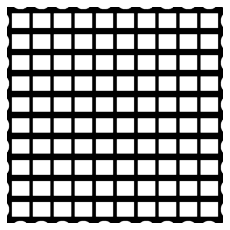

carre_10_0_6_6 error : 2.62
123386


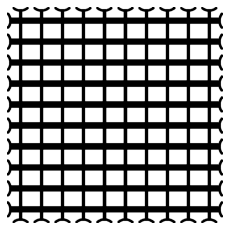

carre_10_1_6_6 error : 9.98
224065


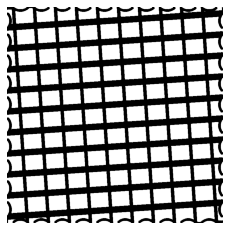

carre_13_0_6_6 error : 3.89
130766


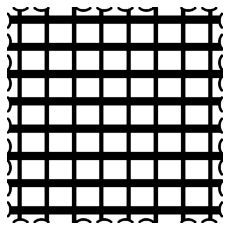

carre_7_0_6_6 error : 3.70
290530


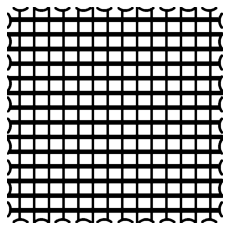

In [16]:
names=['carre_10_0_0_0', 'carre_10_0_6_6', 'carre_10_1_6_6','carre_13_0_6_6','carre_7_0_6_6',]

for name in names:
    print(f'{name} error : {data[name].get_error((0,3)):.2f}')
    data[name].show_geo()
    plt.subplots_adjust(top=1.0,bottom=0.0,left=0.0,right=1.0,hspace=0.2,wspace=0.25)
    plt.savefig(f'images/{name}_{data[name].get_error((0,3)):.2f}.jpg', pil_kwargs={'quality': 60})
    plt.show()

# bests = get_best_test(data, (0,3), 10)
# for test in bests:
#     print(f'{test.test_id} error : {test.get_error((0,3)):.2f}')
#     test.show_geo()
#     plt.subplots_adjust(top=1.0,bottom=0.0,left=0.0,right=1.0,hspace=0.2,wspace=0.25)
#     plt.savefig(f'images/best/{test.test_id}_{test.get_error((0,3)):.2f}.jpg', pil_kwargs={'quality': 60})
#     plt.show()

# worse = get_worse_test(data, (0,3), 10)
# for test in worse:
#     print(f'{test.test_id} error : {test.get_error((0,3)):.2f}')
#     test.show_geo()
#     plt.subplots_adjust(top=1.0,bottom=0.0,left=0.0,right=1.0,hspace=0.2,wspace=0.25)
#     plt.savefig(f'images/worse/{test.test_id}_{test.get_error((0,3)):.2f}.jpg', pil_kwargs={'quality': 60})
#     plt.show()



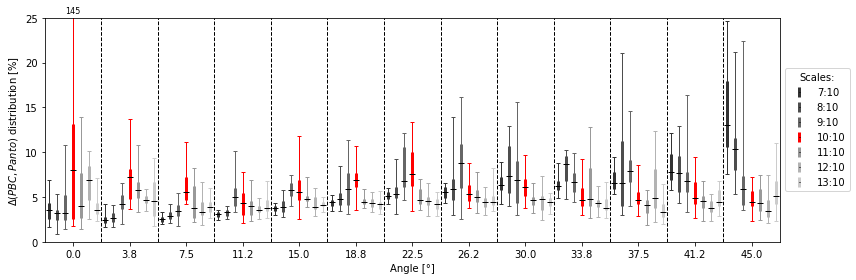

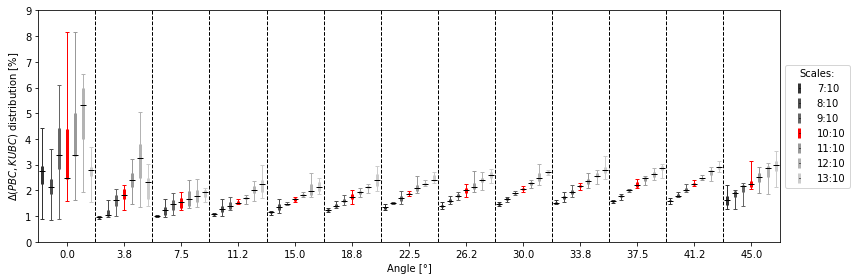

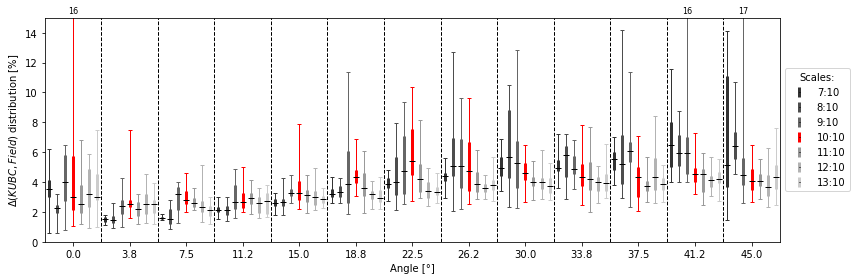

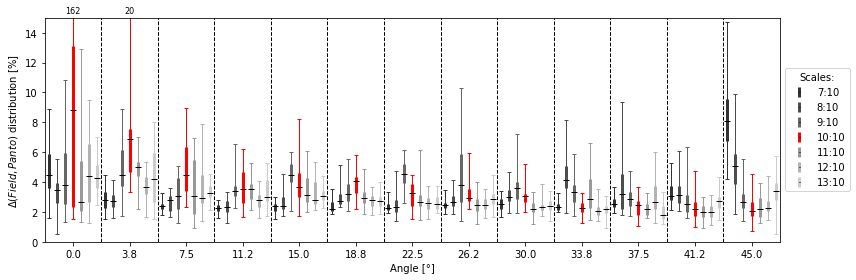

In [17]:


plot_map_theta_size(data, (13, 7, 7, 7),eoi=(0,3), error=r'$\Delta (PBC,Panto)$', angle_max=45.0, ymax=25, loop=False)
plt.savefig('images/map_carre_eoi_03.pdf')
plot_map_theta_size(data, (13, 7, 7, 7),eoi=(0,1), error=r'$\Delta (PBC,KUBC)$', angle_max=45.0, ymax=9, loop=False)
plt.savefig('images/map_carre_eoi_01.pdf')
plot_map_theta_size(data, (13, 7, 7, 7),eoi=(1,2), error=r'$\Delta (KUBC,Field)$', angle_max=45.0, ymax=15, loop=False)
plt.savefig('images/map_carre_eoi_12.pdf')
plot_map_theta_size(data, (13, 7, 7, 7),eoi=(2,3), error=r'$\Delta (Field,Panto)$', angle_max=45.0, ymax=15, loop=False)
plt.savefig('images/map_carre_eoi_23.pdf')

On peut remarquer les points suivants:
- Le motif 10/10 est clairement à eviter car il présente des erreurs très importante.
- De 0 à 17° le motif 7/10 est le meilleur et de 17 à 45° le motif 13/10 devient plus interessant.
- L'angle avec le moins d'erreur est 5.6°.

In [18]:
np.set_printoptions(precision=2)
print(np.array(data['carre_7_0_0_0'].K_plane_stress_PBC))
print(np.array(data['carre_7_16_0_0'].K_plane_stress_PBC))
print(np.array(data['carre_7_16_0_0'].K_panto_dic))
data['carre_7_16_0_0'].show_geo()
data['carre_7_16_0_0'].get_error((0,3))

[[4.35e+01 2.36e+00 4.62e-05]
 [2.36e+00 2.34e+01 1.13e-04]
 [4.62e-05 1.13e-04 6.28e-01]]


KeyError: 'carre_7_16_0_0'

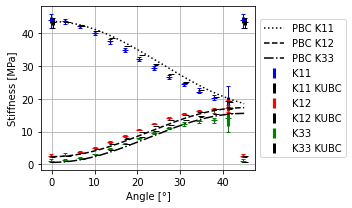

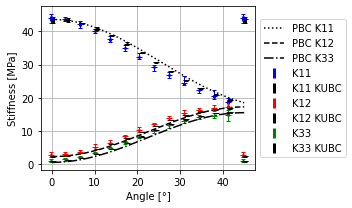

In [ ]:
data_scale_7 = get_tests_by_test_id(data, index=1, target='7')
data_scale_8 = get_tests_by_test_id(data, index=1, target='8')
data_scale_9 = get_tests_by_test_id(data, index=1, target='9')
data_scale_10 = get_tests_by_test_id(data, index=1, target='10')
data_scale_11 = get_tests_by_test_id(data, index=1, target='11')
data_scale_12 = get_tests_by_test_id(data, index=1, target='12')
data_scale_13 = get_tests_by_test_id(data, index=1, target='13')
plot_coef_matrix_per_angle(data_scale_7, (13, 7, 7, 7), angle_max=45.0)
plt.savefig('images/map_carre_coef_7.pdf')
plot_coef_matrix_per_angle(data_scale_13, (13, 7, 7, 7), angle_max=45.0)
plt.savefig('images/map_carre_coef_13.pdf')

In [ ]:
def get_tests_by_test_id2(data, index: int, target: list[str]) -> dict[Test]:
    """ return a dict of test based on the test_id with _ split"""
    new_dict = {}
    for key in data:
        if key.split('_')[index] in target:
            new_dict |= {key: data[key]}
    return new_dict

coefs=((0,0),(1,0),(2,2))


data_no_CC=get_tests_by_test_id2(data_scale_7, index=2, target=[str(i) for i  in ['3']])
for coef in coefs:
    K33_dev_mean_noCC=0.0
    for _,test in data_no_CC.items():
        k33=test.K_panto_dic[coef[0]][coef[1]]
        k33_pbc=test.K_plane_stress_PBC[coef[0]][coef[1]]
        K33_dev_mean_noCC += abs(k33-k33_pbc)
    K33_dev_mean_noCC=K33_dev_mean_noCC/len(data_no_CC)



    print(f'Ecart absolu {coef=}: \nNo CC: {K33_dev_mean_noCC:.2f}')

print(np.array(test.K_plane_stress_PBC))

Ecart absolu coef=(0, 0): 
No CC: 0.50
Ecart absolu coef=(1, 0): 
No CC: 0.53
Ecart absolu coef=(2, 2): 
No CC: 0.45
[[41.84  3.62  5.61]
 [ 3.62 22.55 -2.68]
 [ 5.61 -2.68  1.88]]


- En terme de coefficient, le 13/10 présente un eplus gande variabilité
- On remarque surtout que pour le 7/10, l'erreur PBC KUBC  discret est de l'ordre de grandeur de l'erreur KUBC theorique - PBC.

D'une manière générale, les mêmes conclusion que le nida peuvent être tirées.

## Erreur liée au support manquant

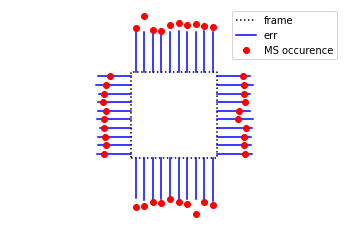

In [ ]:
def plot_err_per_MS(data: dict[Test], eoi: tuple = (0, 3), factor: tuple = (20,20)):
    plt.figure()
    plt.axis('equal')
    plt.plot([], [], 'k:', label='frame')
    plt.plot([], [], 'b', label='err')
    plt.plot([], [], 'ro', label='MS occurence')
    plt.legend()
    # * plot the square shape of the machine
    plt.plot([-1, 1, 1, -1, -1], [-1, -1, 1, 1, -1], 'k:')
    mean_err = np.zeros((4, 10))
    counter_err = np.zeros((4, 10))
    for _, test in data.items():
        mean_err = mean_err+test.get_error(eoi)*test.get_MS()
        counter_err = counter_err+test.get_MS()
    mean_err = mean_err/counter_err
    mean_err=1*mean_err/np.max(mean_err)
    counter_err = counter_err/len(data)
    counter_err=1.3*counter_err/np.max(counter_err)
    for cote in range(4):
        for cyl in range(10):
            if cote % 2 == 0:
                plt.plot([-0.9+cyl/5]*2, [-1+cote, (-1+cote)
                                          * (1+mean_err[cote, cyl])], 'b')
                plt.plot([-0.9+cyl/5], [(-1+cote) *
                                        (1+counter_err[cote, cyl])], 'ro')
            else:
                plt.plot([2-cote, (2-cote)*(1+mean_err[cote, cyl])],
                         [-0.9+cyl/5]*2, 'b')
                plt.plot([(2-cote)*(1+counter_err[cote, cyl])],
                         [-0.9+cyl/5], 'ro')
    
    plt.axis('off')
    plt.show()


plot_err_per_MS(data)


On remarque que tous les cylindres ont la même chance d'être absent mais que ceux dans les coins haut droit et bas gauche entrainnent une erreur légèrement supérieure en moyenne

data


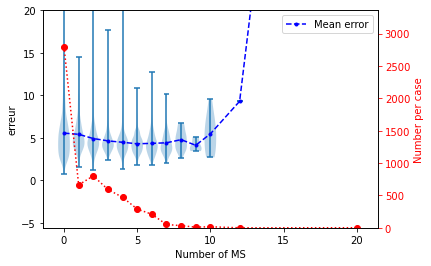

data_scale_7


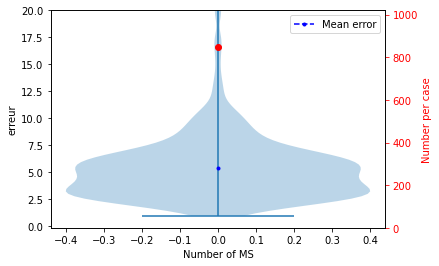

data_scale_8


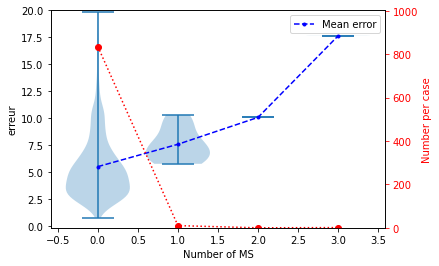

data_scale_9


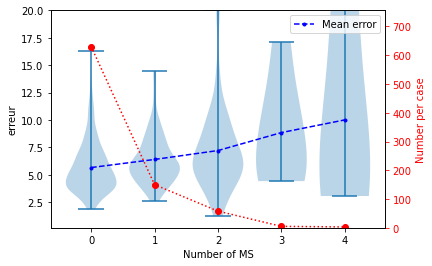

data_scale_10


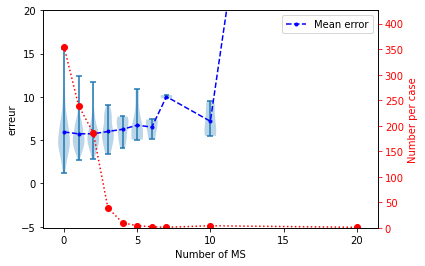

data_scale_11


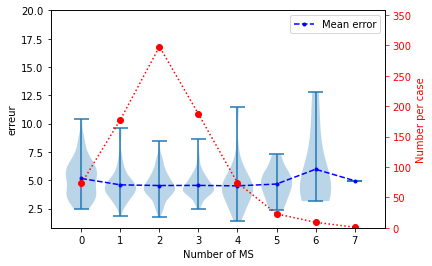

data_scale_12


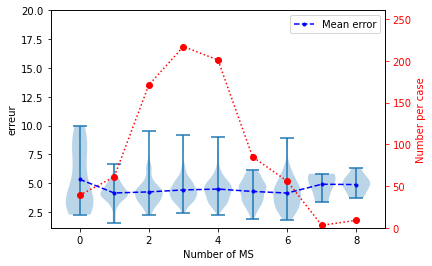

data_scale_13


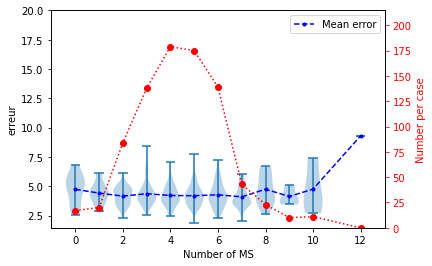

In [ ]:

def err_per_number_of_ms(data: dict[Test], eoi:tuple=(0,3), step:float=0.9, width:float=0.1) -> None:
    x_scatter, y_scatter = [], []
    for _, test in data.items():
        err = test.get_error(eoi)
        number_missing_support = sum([len(i) for i in test.skipped_cyl])
        x_scatter.append(number_missing_support)
        y_scatter.append(err)

    X_sorted, Y_sorted = (list(t) for t in zip(*sorted(zip(x_scatter, y_scatter))))
    old = X_sorted[0]
    X_bulk, Y_bulk, number_per_x= [old], [[]], []
    counter=0
    for x, y in zip(X_sorted, Y_sorted):
        if x<old+step:
            Y_bulk[-1].append(y)
            counter+=1
            continue
        number_per_x.append(counter)
        X_bulk.append(x)
        Y_bulk.append([y])
        old = x
        counter=0
    number_per_x.append(counter)
    y_mean = []
    for y in Y_bulk:
        y_mean.append(np.mean(np.array(y)))
    y_mean = np.array(y_mean)

    plt.violinplot(Y_bulk, X_bulk,widths=width,
                   showmeans=False, showmedians=False, showextrema=True)
    plt.plot(X_bulk, y_mean, '.b--', label='Mean error')
    plt.xlabel(f'Number of MS')
    plt.ylim(top=20)
    plt.ylabel('erreur')
    plt.legend()
    ax2=plt.twinx()
    ax2.set_ylim(bottom=0, top=1.2*np.max(number_per_x))
    ax2.plot(X_bulk, number_per_x, 'ro:')
    ax2.set_ylabel('Number per case', color='r')
    ax2.tick_params(axis='y', colors='red')
    plt.show()

to_plot=['data', 'data_scale_7','data_scale_8', 'data_scale_9', 'data_scale_10', 
         'data_scale_11', 'data_scale_12', 'data_scale_13']
#to_plot=['data']

for i in to_plot:
    print(i)
    err_per_number_of_ms(eval(i), width=0.8)

- La perte ne 1 ou plusieur cylindre n'entraine pas nécéssairement une augmentation significative de l'erreur. Ce n'est pas un critère suffisant. C'est certe pertinent quand on considère tous les tests mais pour les 7 et 8/10 il ne manque aucun cylindre. 
- L'etude de l'erreur la le nombre manquant de cylindre ne semble donc pas pertinante.

carre_7_0_4_4
0.9919530827573062


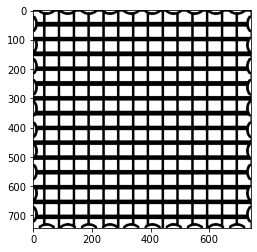

In [ ]:

best_t=get_best_test(data_scale_7,number=1)
# %matplotlib qt 
for t in best_t:
    print(t.test_id)
    print(t.get_error((0,3)))
    t.show_geo()


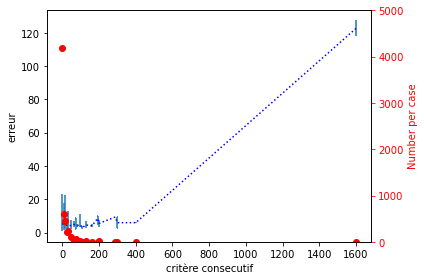

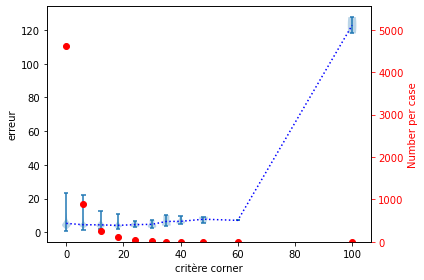

In [ ]:

eoi=(0,3)

err=[]
criteria=[]
for _,test in data.items():
    err.append(test.get_error(eoi))
    criteria.append(get_max_MS_consecutive(test)*test.get_number_ms())

plot_box2(criteria,err, step=5, ylabel=f'critère consecutif', width=3)
    

def get_mean_MS_worse_corner2(test: Test) -> float:
    mat_MS = test.get_MS()
    mat_MS_corner = test.get_MS_corner()
    return np.max(2*np.sum(mat_MS_corner, axis=1))*test.get_number_ms()

err=[]
criteria=[]
for _,test in data.items():
    err.append(test.get_error(eoi))
    criteria.append(get_mean_MS_worse_corner2(test))

plot_box2(criteria,err, step=5, ylabel=f'critère corner', width=3)

Ces différents critères ne semble pas apporter d'information significative. D'autant plus que la base de données contient également les essais 7 et 8/10 qui n'ont jamais de support manquant.

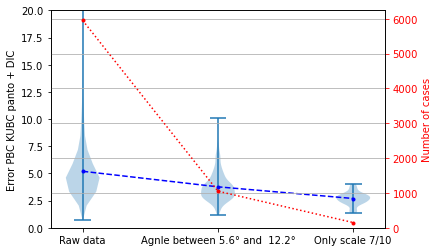

WORSE
carre_7_3_4_0
4.058872239335475


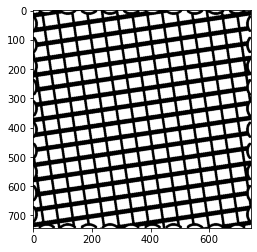

carre_7_3_6_0
4.057421442368537


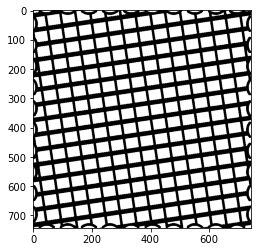

BEST
carre_7_2_9_2
1.3210540439087364


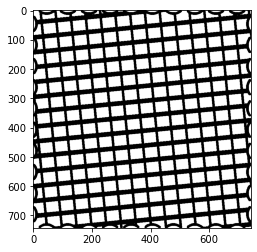

carre_7_2_1_1
1.3519767952108404


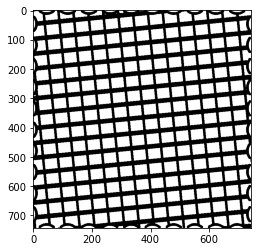

In [ ]:

data_raw = data
data_list = [[], [], []]
last_tests_dict={}
eoi = (0, 3)
for test_id, test in data_raw.items():
    # * list of conditions
    stage = 0
    data_list[stage].append(test.get_error(eoi))
    
    if test.test_id.split('_')[2] not in ['2', '3', '4']:  # * Si l'angle est de 0 ou 15°
        continue
    stage += 1
    data_list[stage].append(test.get_error(eoi))

    if test.test_id.split('_')[1] not in ['7']:
        continue
    stage += 1
    data_list[stage].append(test.get_error(eoi))
    last_tests_dict |= {test_id:test}


plt.figure()
plt.violinplot(data_list, range(len(data_list)), widths=0.25,
               showmeans=False, showmedians=False, showextrema=True)

plt.plot(range(len(data_list)), [np.mean(np.array(i)) for i in data_list], 'b.--')

plt.xticks(range(len(data_list)), ['Raw data', 'Agnle between 5.6° and  12.2°', 'Only scale 7/10'])
plt.ylim(bottom=0.0, top=20)
plt.ylabel('Error PBC KUBC panto + DIC')
plt.twinx()
plt.plot(range(len(data_list)), [len(i) for i in data_list], 'r.:')
plt.ylabel('Number of cases', color='r')
plt.tick_params(axis='y', colors='red')
plt.ylim(bottom=0.0)
plt.grid()
plt.show()

print('WORSE')
wb_tests=get_worse_test(last_tests_dict,number=2)
for t in wb_tests:
    print(t.test_id)
    print(t.get_error((0,3)))
    t.show_geo()

print('BEST')
wb_tests=get_best_test(last_tests_dict,number=2)
for t in wb_tests:
    print(t.test_id)
    print(t.get_error((0,3)))
    t.show_geo()


En observant les meilleurs et pires test, ont peut en déduire des régles à l'oeil afin de limiter les min et max. On remarque ici qu'enlever les orientation 0 et 30 permet ici de réduire le max et même d'améliorer la moyenne.

## Effet des CC

Etude de l'effet des CC sur le NIDA taille 7/10

Lecture des données réalisée en 0.22986s


<ipython-input-20-aba770b48f4f>:25: RuntimeWarning: Mean of empty slice
  error_per_angle_mean = np.nanmean(error_per_angle, axis=(2, 3))
/usr/lib/python3/dist-packages/numpy/lib/nanfunctions.py:1389: RuntimeWarning: All-NaN slice encountered
  result = np.apply_along_axis(_nanquantile_1d, axis, a, q,
<ipython-input-20-aba770b48f4f>:28: RuntimeWarning: All-NaN slice encountered
  error_per_angle_min = np.nanmin(error_per_angle, axis=(2, 3))
<ipython-input-20-aba770b48f4f>:29: RuntimeWarning: All-NaN slice encountered
  error_per_angle_max = np.nanmax(error_per_angle, axis=(2, 3))


IndexError: list index out of range

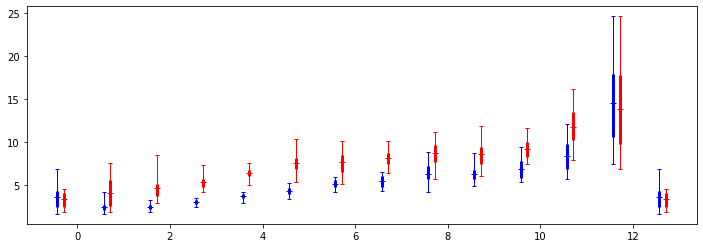

In [20]:
data_no_CC = data_scale_7
data_CC = get_bulk_data(read_data_from_campaigns(['campagne_carre_CC']))

bulk_data = data_no_CC | data_CC


N_theta, N_type, N_tx, N_ty = (13, 7, 7, 7)
eoi = (0, 3)

error_per_angle = np.empty((N_theta+1, N_type, N_tx, N_ty))
error_per_angle[:] = np.nan
for test_id, test in bulk_data.items():
    scale, angle, idx, idy = tuple(map(int, test_id.split('_')[1:]))
    if test_id.split('_')[0][-1]=='C':
        cc=1
    else:
        cc=0

    error_per_angle[angle, cc, idx,
                    idy] = test.get_error(eoi)
    if angle == 0:
        error_per_angle[-1, cc, idx,
                        idy] = test.get_error(eoi)

error_per_angle_mean = np.nanmean(error_per_angle, axis=(2, 3))
error_per_angle_q1 = np.nanquantile(error_per_angle, 0.25, axis=(2, 3))
error_per_angle_q2 = np.nanquantile(error_per_angle, 0.75, axis=(2, 3))
error_per_angle_min = np.nanmin(error_per_angle, axis=(2, 3))
error_per_angle_max = np.nanmax(error_per_angle, axis=(2, 3))

plt.figure(figsize=(12, 4))
x = np.linspace(0, N_theta, N_theta+1)-0.5+1/N_type/2
col = ['b', 'r', 'r', 'm', 'k', 'c', 'y']
leg = ['No CC', 'With CC']

for scale in range(N_type):
    plt.errorbar(x+scale/N_type, error_per_angle_mean[:, scale], [error_per_angle_mean[:, scale]-error_per_angle_q1[:, scale], error_per_angle_q2[:, scale] - error_per_angle_mean[:, scale]],
                 fmt=col[scale]+'_', lw=3, ms=1, label=f'{leg[scale]}')
    plt.errorbar(x+scale/N_type, error_per_angle_mean[:, scale], [error_per_angle_mean[:, scale]-error_per_angle_min[:, scale], error_per_angle_max[:, scale] - error_per_angle_mean[:, scale]],
                 fmt='_'+col[scale], ecolor=col[scale], lw=1, capsize=2)
    for i, m in enumerate(error_per_angle_max[:, scale]):
        if m > 30.0:
            plt.text(x[i]+scale/N_type,
                     30.0, f'{m:.0f}', ha='center', fontsize=8)

for i in range(12):
    plt.axvline(x=i+0.5, color='k', ls='--', lw=1.0)

plt.ylim(bottom=0)
plt.xlim((-0.5, 12.5))
plt.xticks(range(13), [f'{2.5*i}°' for i in range(13)])
plt.legend()
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('Angle [°]')
plt.ylabel(f'Error distribution [%]')
plt.tight_layout()
plt.show()

print(np.mean(error_per_angle_mean, axis=0))

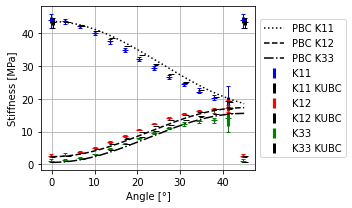

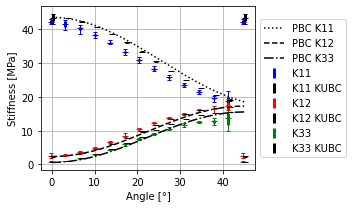

In [22]:
plot_coef_matrix_per_angle(data_scale_7, (13, 7, 7, 7), angle_max=45.0)
plot_coef_matrix_per_angle(data_CC, (13, 7, 7, 7), angle_max=45.0)

Les CC semble surtout amélioirer la mesure du coef K33 de la matrice de rigidité. Dans la suite on quantifie l'amélioration moyenne de l'erreur.

In [23]:
coefs=((0,0),(1,0),(2,2))
for coef in coefs:
    K33_dev_mean_noCC=0.0
    for _,test in data_no_CC.items():
        k33=test.K_panto_dic[coef[0]][coef[1]]
        k33_pbc=test.K_plane_stress_PBC[coef[0]][coef[1]]
        K33_dev_mean_noCC += abs(k33-k33_pbc)/k33_pbc
    K33_dev_mean_noCC=K33_dev_mean_noCC/len(data_no_CC)*100

    K33_dev_mean_CC=0.0
    for _,test in data_CC.items():
        k33=test.K_panto_dic[coef[0]][coef[1]]
        k33_pbc=test.K_plane_stress_PBC[coef[0]][coef[1]]
        K33_dev_mean_CC += abs(k33-k33_pbc)/k33_pbc
    K33_dev_mean_CC=K33_dev_mean_CC/len(data_CC)*100

    print(f'Erreur moyenne [%] {coef=}: \nNo CC: {K33_dev_mean_noCC:.1f}\nCC:    {K33_dev_mean_CC:.1f}')

Erreur moyenne [%] coef=(0, 0): 
No CC: 2.4
CC:    5.0
Erreur moyenne [%] coef=(1, 0): 
No CC: 7.7
CC:    6.6
Erreur moyenne [%] coef=(2, 2): 
No CC: 15.7
CC:    11.6


La découpe a un effet (en moyenne) très bénéfique sur la mesure. L'erreur sur le coef K33 passe de 11 à 5%!

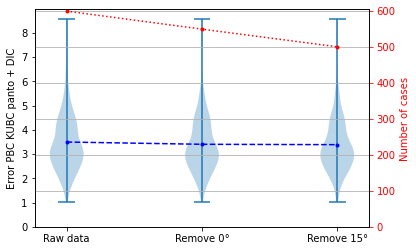

In [ ]:

data_raw = data_CC
data_list = [[], [], []]
last_tests_dict={}
eoi = (0, 3)
for test_id, test in data_raw.items():
    # * list of conditions
    stage = 0
    data_list[stage].append(test.get_error(eoi))

    if test.test_id.split('_')[2] in ['0']:  # * Si l'angle est de 0 ou 15°
        continue
    stage += 1
    data_list[stage].append(test.get_error(eoi))

    if test.test_id.split('_')[2] in ['6']:
        continue
    stage += 1
    data_list[stage].append(test.get_error(eoi))
    last_tests_dict |= {test_id:test}


plt.figure()
plt.violinplot(data_list, range(len(data_list)), widths=0.25,
               showmeans=False, showmedians=False, showextrema=True)

plt.plot(range(len(data_list)), [np.mean(np.array(i)) for i in data_list], 'b.--')

plt.xticks(range(len(data_list)), ['Raw data', 'Remove 0°', 'Remove 15°'])
plt.ylim(bottom=0.0)
plt.ylabel('Error PBC KUBC panto + DIC')
plt.twinx()
plt.plot(range(len(data_list)), [len(i) for i in data_list], 'r.:')
plt.ylabel('Number of cases', color='r')
plt.tick_params(axis='y', colors='red')
plt.ylim(bottom=0.0)
plt.grid()
plt.show()

# print('WORSE')
# wb_tests=get_worse_test(last_tests_dict,number=1)
# for t in wb_tests:
#     print(t.test_id)
#     print(t.get_error((0,3)))
#     t.show_geo()

# print('BEST')
# wb_tests=get_best_test(last_tests_dict,number=1)
# for t in wb_tests:
#     print(t.test_id)
#     print(t.get_error((0,3)))
#     t.show_geo()

Contrairement au cas sans découpe, enlever les orientation 0 et30° n'améliore pas le max ni la moyenne. On cherche à déterminer dans ce qui suit, pourquoi dans certain cas la découpe améliore la mésure, et dans d'autre non.

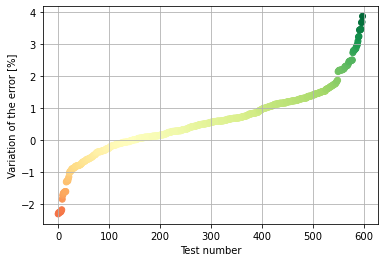

Amélioration moyenne : 0.5891652754590984
Tests pour qui ca a le mieux marché
honeyCC_7_0_5_0 avec un évolution de 3.88


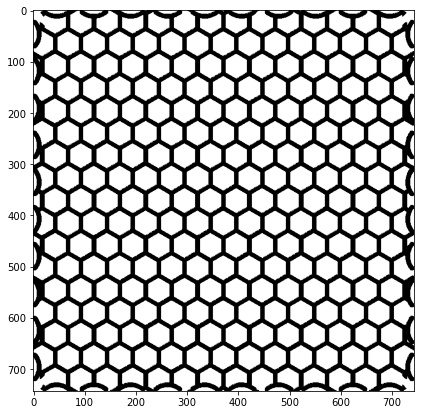

Tests pour qui ca a le moins bien marché
honeyCC_7_4_7_4 avec un évolution de -2.3


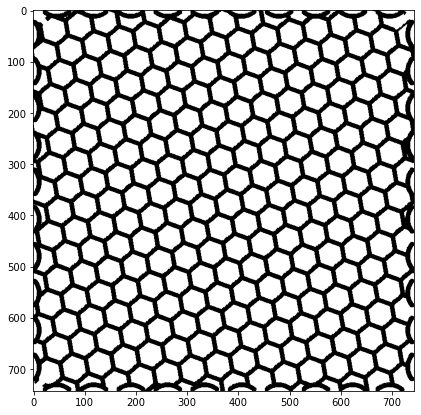

In [ ]:
""" Understand whyl in some cases the CC is better and sometime no"""
# data_CC
# data_no_CC
changes=[]
names=[]
eoi=(0,3)
for test_id,test in data_CC.items():
    changes.append(-test.get_error(eoi)+data_no_CC[test_id[:5]+test_id[7:]].get_error(eoi))
    names.append(test_id)


changes, names=[list(i) for i in zip(*sorted(zip(changes, names)))]

plt.scatter(range(len(changes)), changes,c=changes, cmap='RdYlGn', vmin=min([min(changes),-max(changes)]))
plt.grid()
plt.xlabel('Test number')
plt.ylabel('Variation of the error [%]')
plt.show()


N=1
print(f'Amélioration moyenne : {np.mean(np.asarray(changes))}')
print('Tests pour qui ca a le mieux marché')
for name, val in zip(names[-N:],changes[-N:]):
    print(f'{name} avec un évolution de {val}')
    plt.figure(figsize=(7,7))
    data_CC[name].show_geo()

print('Tests pour qui ca a le moins bien marché')
for name, val in zip(names[:N],changes[:N]):
    print(f'{name} avec un évolution de {val}')
    plt.figure(figsize=(7,7))
    data_CC[name].show_geo()



On remarque que dans environ 150 cas sur 600, la découpe dans les coins augmente l'erreur. En observant les cas, on remarque que cela intervient lorsque la déoupe entaille une barre dans la longueur. Ces cas pourront être éliminés à la main.

# Etude de l'effet lié à la libre rotation des cylindres

In [ ]:
data_scale_13_UR3 = get_bulk_data(read_data_from_campaigns(['campagne_carre_UR3_S13']))


bulk_data = data_scale_13 | data_scale_13_UR3


N_theta, N_type, N_tx, N_ty = (12, 2, 10, 5)
EOI = (0, 3)

error_per_angle = np.empty((N_theta+1, N_type, N_tx, N_ty))
error_per_angle[:] = np.nan
for test_id, test in bulk_data.items():
    scale, angle, idx, idy = tuple(map(int, test_id.split('_')[1:]))
    
    if test_id.split('_')[0][-1]=='3':
        cc=1
    else:
        cc=0

    error_per_angle[angle, cc, idx,
                    idy] = test.global_err[EOI[0]][EOI[1]]
    if angle == 0:
        error_per_angle[-1, cc, idx,
                        idy] = test.global_err[EOI[0]][EOI[1]]

error_per_angle_mean = np.nanmean(error_per_angle, axis=(2, 3))
error_per_angle_q1 = np.nanquantile(error_per_angle, 0.25, axis=(2, 3))
error_per_angle_q2 = np.nanquantile(error_per_angle, 0.75, axis=(2, 3))
error_per_angle_min = np.nanmin(error_per_angle, axis=(2, 3))
error_per_angle_max = np.nanmax(error_per_angle, axis=(2, 3))

plt.figure(figsize=(12, 4))
x = np.linspace(0, N_theta, N_theta+1)-0.5+1/N_type/2
col = ['b', 'r', 'r', 'm', 'k', 'c', 'y']
leg = ['Free rot UR3', 'UR3 = 0']

for scale in range(N_type):
    plt.errorbar(x+scale/N_type, error_per_angle_mean[:, scale], [error_per_angle_mean[:, scale]-error_per_angle_q1[:, scale], error_per_angle_q2[:, scale] - error_per_angle_mean[:, scale]],
                 fmt=col[scale]+'_', lw=3, ms=1, label=f'{leg[scale]}')
    plt.errorbar(x+scale/N_type, error_per_angle_mean[:, scale], [error_per_angle_mean[:, scale]-error_per_angle_min[:, scale], error_per_angle_max[:, scale] - error_per_angle_mean[:, scale]],
                 fmt='_'+col[scale], ecolor=col[scale], lw=1, capsize=2)
    for i, m in enumerate(error_per_angle_max[:, scale]):
        if m > 30.0:
            plt.text(x[i]+scale/N_type,
                     30.0, f'{m:.0f}', ha='center', fontsize=8)

for i in range(12):
    plt.axvline(x=i+0.5, color='k', ls='--', lw=1.0)

plt.ylim(bottom=0)
plt.xlim((-0.5, 12.5))
plt.xticks(range(13), [f'{2.5*i}°' for i in range(13)])
plt.legend()
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('Angle [°]')
plt.ylabel(f'Error distribution [%]')
plt.tight_layout()
plt.show()

print(np.mean(error_per_angle_mean, axis=0))

FileNotFoundError: [Errno 2] No such file or directory: '/data0/usrtmp/valmalette/abakubc/campagne_carre_UR3_S13.csv'

La libre rotation des cylindres est très importante lorsque le motif est grand car chaque support est connecté via (en générale) à une unique poutre (-> effet de l'angle d'incidence et de la position).
Il serait peut-être pertinent de refaire ce mapping avec UR3 bloqué avec le motif 7/10 pour montrer que la liason support motif est bien la composante décisive pour améliorer l'erreur dans le cas de grands motifs.

[[        nan -0.23863636  0.          0.28409091         nan -0.375
   0.15909091 -0.06818182 -0.09090909  0.09090909]
 [ 0.19318182  0.06818182 -0.25        0.13636364 -0.35227273         nan
   0.                 nan -0.06818182  0.18181818]
 [ 0.04444444  0.31111111         nan -0.31111111  0.01111111  0.13333333
  -0.17777778  0.3                nan -0.4       ]
 [        nan  0.17777778 -0.04444444  0.13333333 -0.32222222  0.07777778
  -0.37777778         nan -0.01111111  0.38888889]]


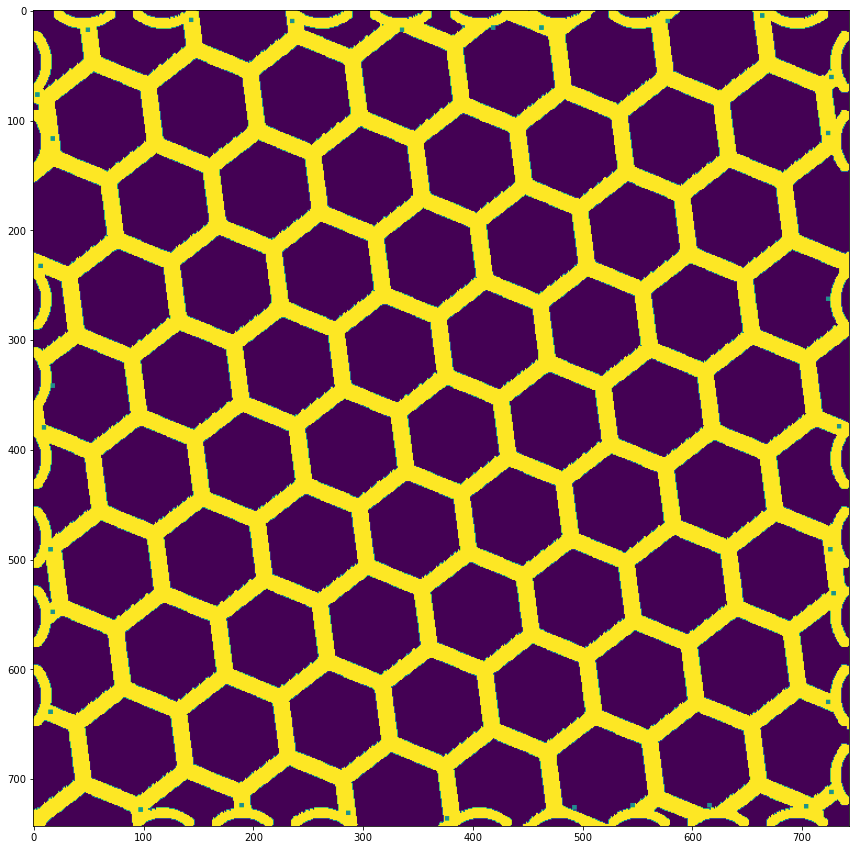

In [ ]:

# ! DEBUG
# %matplotlib


def get_circle(center, radius: float, PIC_SIZE) -> list[list]:
    """return a list of pix """
    center = np.array(center)
    l = []
    N = 500
    for i in range(N):
        x = int(center[0]+radius*cos(2*pi*i/N))
        y = int(center[1]+radius*sin(2*pi*i/N))
        if [x, y] not in l and x >= 0 and y >= 0 and x < PIC_SIZE and y < PIC_SIZE:
            l.append([x, y])
    return l


def init_pix():
    DIST_FROM_EDGE = 10.0
    SMALL_RADIUS = 13.0
    BIG_RADIUS = 16.0
    DIST_FROM_CORNER_EDGE = 18.0
    PAS = 28.0
    L = 288.0

    PIC_SIZE = 743  # square shape
    SCALE = PIC_SIZE/L
    centers = np.zeros((4, 10, 2))
    for cote in range(4):
        for cyl in range(10):
            if cote % 2 == 1:
                x = - cyl*PAS*SCALE + (L-DIST_FROM_CORNER_EDGE)*SCALE
                y = L*SCALE+DIST_FROM_EDGE*SCALE if cote == 1 else -DIST_FROM_EDGE*SCALE
            else:
                x = L*SCALE+DIST_FROM_EDGE*SCALE if cote == 0 else -DIST_FROM_EDGE*SCALE
                y = cyl*PAS*SCALE + DIST_FROM_CORNER_EDGE*SCALE
            centers[cote, cyl, :] = np.array([int(x), int(y)])
    supports_lists = [[], [], [], []]

    for co in range(4):
        for cy in range(10):
            pix_list = get_circle(
                centers[co, cy, :], 1.06*SCALE*BIG_RADIUS, PIC_SIZE)
            if co % 2 == 0:
                pix_list = sorted(pix_list, key=lambda x: x[1])
            else:
                pix_list = sorted(pix_list, key=lambda x: x[0])

            supports_lists[co].append(Support(pix_list))

    return supports_lists


def draw_circle(img, pix_list, val=0.0):
    for p in pix_list:
        img[p[0], p[1]] = val
    return img


class Support:
    def __init__(self, pix_list) -> None:
        self.pix_list = pix_list


def compute_support_links(test, supports_lists):
    support_links = np.zeros((4, 10))
    support_links[:] = np.nan
    for co in range(4):
        for cy in range(10):
            if cy not in test.skipped_cyl[co]:
                pix_list = supports_lists[co][cy].pix_list
                img = test.get_geo()
                s = 0
                s_counter = 0.0
                for i, p in enumerate(pix_list):
                    if img[p[0], p[1]] == 1.0:
                        s += i
                        s_counter += 1
                moyenne = int(s/s_counter)
                support_links[co, cy] = moyenne/len(pix_list)-0.5
                img2[pix_list[moyenne][0]-2:pix_list[moyenne][0]+2,
                     pix_list[moyenne][1]-2:pix_list[moyenne][1]+2]=0.5
    test.support_links = support_links
    return support_links

t=data_scale_7[list(data_scale_7.keys())[1]]
img = test.get_geo()
img2=np.copy(img)
supports_lists = init_pix()
print(compute_support_links(test, supports_lists))
plt.figure(figsize=(15,15))
plt.imshow(img2)

# Regles de conception

- Choisir un motif de taille éloignée de 10/10.
- Ne pas aligner le motif sur le cadre (eg 0° ou 30° pour le nida, 0 et 45° pour le carre). Il semblerai qu'un angle proche de 0° (mais différent de 0) soit une bonne option.
- Faire une découpe dans les coins mais ne pas couper une barre dans sa longueur.
- quitte à perdre un cylindre, il vaut mieux ne pas le perdre dans le coins en haut à droite et en  bas à gauche (très léger).
  